# 02 Carbon emissions and climate change

**Questions**
1. How have emissions in African countries changed since 2000, and how do they compare with the world?
2. Which countries have seen the largest increases in emissions?
3. Is higher income associated with higher CO2 per capita?
4. Which countries have reduced the CO2 intensity of their economies?

**What I expect going in**
- **H1** CO2 per capita is higher in richer African countries (tested formally in `08 Panel Models`).
- **H2** CO2 intensity of GDP has fallen in most African countries since 2000.

**Read before interpreting:** the World Bank (EDGAR) series exclude land-use change, which is the largest source for forest economies (section 6 shows the gap). Percentage growth from very small bases is suppressed below a materiality floor.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3,
                     "figure.dpi": 110, "font.size": 9})
BLUE, GREY, RED, GREEN = "#1f4e79", "#7f7f7f", "#c00000", "#2f6f4f"

DATA = Path("data")
OUT = Path("outputs") / "02 carbon"
OUT.mkdir(parents=True, exist_ok=True)
for f in OUT.glob("*"):
    f.unlink()          # start each run with an empty outputs folder

obs = pd.read_csv(DATA / "observations.csv", dtype={"flag": str})        # long: iso3, year, indicator_id, value, source, flag
panel = pd.read_csv(DATA / "panel.csv")                # wide: one row per country-year
ind = pd.read_csv(DATA / "indicators.csv").set_index("indicator_id")
cty = pd.read_csv(DATA / "countries.csv").set_index("iso3")
AFRICA = cty.index[cty["group"] == "Africa"].tolist()
name = cty["country_name"].to_dict()
af = obs[obs["iso3"].isin(AFRICA)]
afp = panel[panel["iso3"].isin(AFRICA)]


def label(i):
    return f"{ind.at[i, 'indicator_name']} ({ind.at[i, 'unit']})" if i in ind.index else i


def has(*ids):
    missing = [i for i in ids if i not in panel.columns]
    if missing:
        print("Not in the data, skipped:", ", ".join(missing))
    return not missing


def latest(i, frame=None, max_age=5):
    """Latest observed value per country. Values more than max_age years older than the
    newest year for that indicator are dropped so stale points do not enter rankings."""
    s = (frame if frame is not None else af)
    s = s[s["indicator_id"] == i].sort_values("year").groupby("iso3").tail(1)
    s = s[s["year"] >= s["year"].max() - max_age]
    return s.assign(country=s["iso3"].map(name)).sort_values("value", ascending=False)[["iso3", "country", "year", "value"]]


def change(i, base=(2000, 2002)):
    """Change from the 2000 to 2002 average (damps single-year noise) to the latest value.
    Percentage change only where the base is above the 10th percentile, so tiny bases
    do not produce meaningless growth rates."""
    s = af[af["indicator_id"] == i]
    b = s[s["year"].between(*base)].groupby("iso3")["value"].mean().rename("base")
    l = s.sort_values("year").groupby("iso3").tail(1).set_index("iso3")[["year", "value"]].rename(columns={"value": "latest", "year": "latest_year"})
    d = l.join(b, how="inner")
    d["abs_change"] = d["latest"] - d["base"]
    floor = d["base"].abs().quantile(0.10)
    d["pct_change"] = np.where(d["base"].abs() > floor, 100 * d["abs_change"] / d["base"].abs(), np.nan)
    d.insert(0, "country", d.index.map(name))
    return d.sort_values("abs_change", ascending=False)


def median_path(i, iso=None):
    """Africa median by year (only years where at least 10 countries report), or one economy's series."""
    if iso:
        s = obs[(obs["indicator_id"] == i) & (obs["iso3"] == iso)]
        return s.set_index("year")["value"].sort_index()
    s = af[af["indicator_id"] == i].groupby("year")["value"].agg(["median", "count"])
    return s.loc[s["count"] >= 10, "median"]


def barh(df, value, title, xlabel, path, n=15, color=BLUE):
    d = df.head(n).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.32 * len(d) + 1))
    ax.barh(d["country"], d[value], color=color)
    for y, (v, yr) in enumerate(zip(d[value], d.get("year", d.get("latest_year", [""] * len(d))))):
        ax.text(v, y, f" {v:,.2f} ({yr})" if yr != "" else f" {v:,.2f}", va="center", fontsize=7)
    ax.set_title(title, loc="left"); ax.set_xlabel(xlabel); ax.grid(axis="y", visible=False)
    fig.tight_layout(); fig.savefig(OUT / path, dpi=150); plt.show()


def save_excel(path, sheets):
    """Tables to Excel in house style: Tahoma 8, bold headers without fill, frozen header, no gridlines."""
    from openpyxl.styles import Font
    with pd.ExcelWriter(OUT / path, engine="openpyxl") as xl:
        for sheet, frame in sheets.items():
            frame.to_excel(xl, sheet_name=sheet[:31])
        for ws in xl.book.worksheets:
            ws.sheet_view.showGridLines = False
            ws.freeze_panes = "B2"
            for row in ws.iter_rows():
                for c in row:
                    c.font = Font(name="Tahoma", size=8, bold=(c.row == 1))
                    if isinstance(c.value, float):
                        c.number_format = "#,##0.00;(#,##0.00);-"
    return sorted(p.name for p in OUT.iterdir())

## 1. Africa against the world

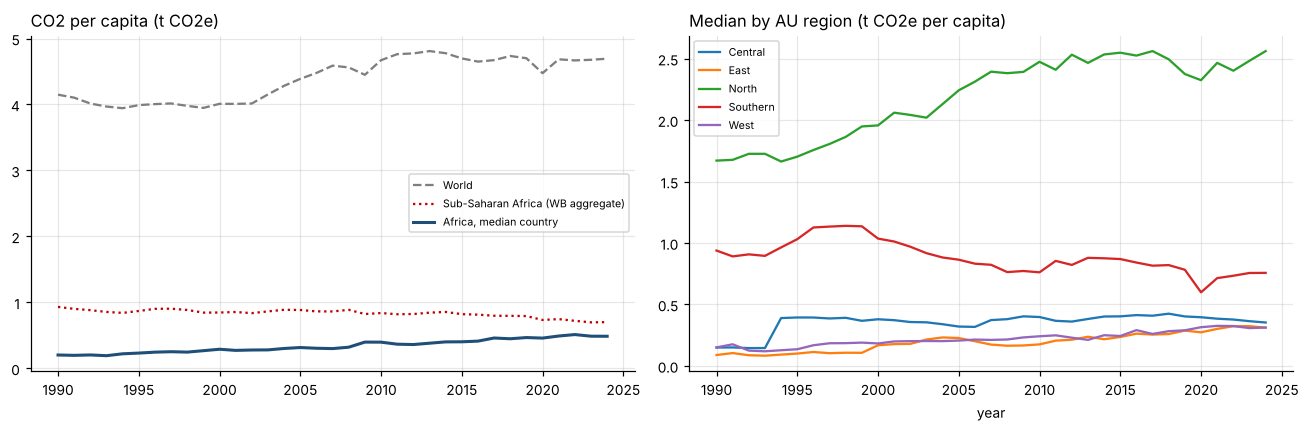

In [2]:
if has("A01"):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for iso, col, ls in (("WLD", GREY, "--"), ("SSF", RED, ":"), ("HIC", "black", "-.")):
        s = median_path("A01", iso)
        if len(s):
            ax[0].plot(s.index, s.values, ls, color=col, label=name.get(iso, iso))
    m = median_path("A01")
    ax[0].plot(m.index, m.values, color=BLUE, lw=2, label="Africa, median country")
    ax[0].set_title("CO2 per capita (t CO2e)", loc="left"); ax[0].legend(fontsize=7)
    reg = afp.groupby(["au_region", "year"])["A01"].median().unstack(0)
    reg.plot(ax=ax[1]); ax[1].set_title("Median by AU region (t CO2e per capita)", loc="left"); ax[1].legend(fontsize=7)
    fig.tight_layout(); fig.savefig(OUT / "co2 per capita trend.png", dpi=150); plt.show()

**The median African country emits about a tenth of the world average per person, and the gap is closing only slowly.**

- The median African country rose from 0.29 t CO2e per person in 2000 to 0.49 t in 2024. The world average moved from 4.0 t to 4.7 t.
- North Africa is the outlier: its median rose from 1.96 t to 2.57 t. Southern Africa's median fell from about 1.0 t to 0.76 t.

## 2. Who emits most, per person and in total

,iso3,country,year,value
1189,LBY,Libya,2024,8.665
1924,SYC,Seychelles,2024,7.237
2204,ZAF,South Africa,2024,6.877
664,DZA,Algeria,2024,3.981
1434,MUS,Mauritius,2024,3.536
279,BWA,Botswana,2024,2.737
2029,TUN,Tunisia,2024,2.621
1014,GNQ,Equatorial Guinea,2024,2.551
699,EGY,Egypt,2024,2.503
804,GAB,Gabon,2024,2.047


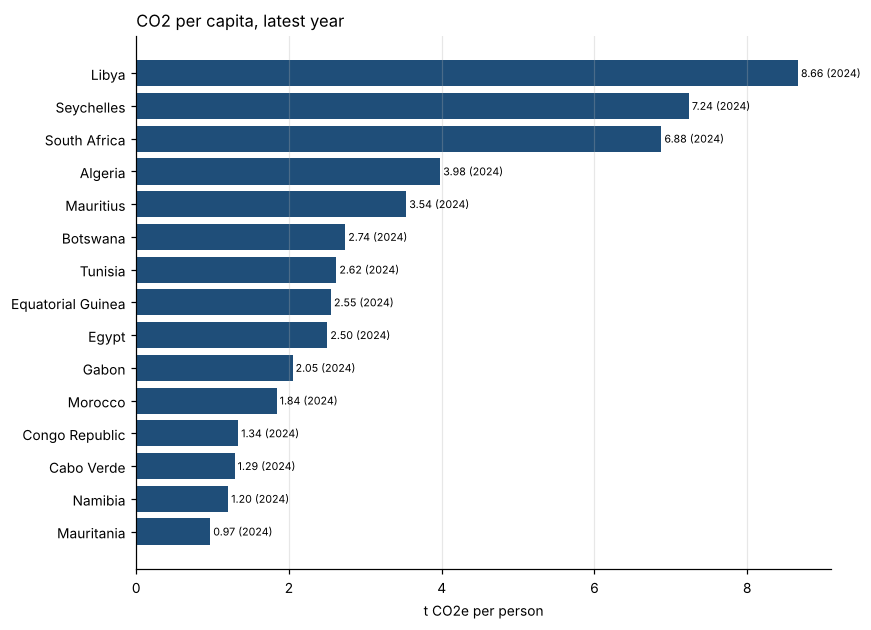

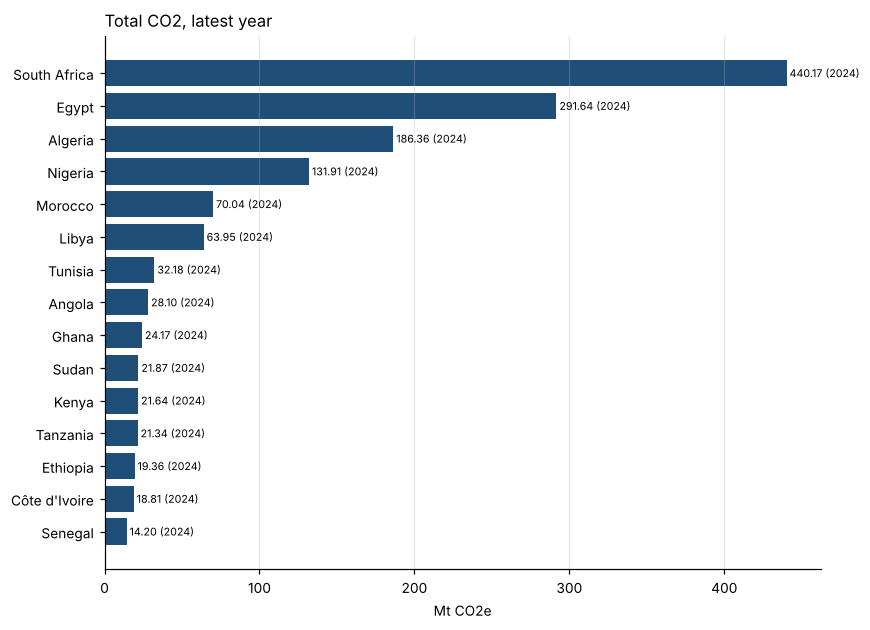

Top 5 emitters' share of Africa's total CO2: 72.7%


,iso3,country,year,value,share_pct
4479,ZAF,South Africa,2024,440.168,28.556
2974,EGY,Egypt,2024,291.639,18.920
2939,DZA,Algeria,2024,186.358,12.090
3849,NGA,Nigeria,2024,131.910,8.558
3534,MAR,Morocco,2024,70.041,4.544
3464,LBY,Libya,2024,63.953,4.149
4304,TUN,Tunisia,2024,32.180,2.088
2379,AGO,Angola,2024,28.100,1.823
3149,GHA,Ghana,2024,24.171,1.568
3954,SDN,Sudan,2024,21.868,1.419


In [3]:
pc, tot = latest("A01"), latest("A02")
display(pc.head(10))
barh(pc, "value", "CO2 per capita, latest year", "t CO2e per person", "co2 per capita ranking.png")
barh(tot, "value", "Total CO2, latest year", "Mt CO2e", "co2 total ranking.png")
share = tot.assign(share_pct=100 * tot["value"] / tot["value"].sum())
print(f"Top 5 emitters' share of Africa's total CO2: {share['share_pct'].head(5).sum():.1f}%")
share.head(10)

**Five countries produce almost three quarters of Africa's fossil CO2.**

- South Africa (440 Mt, 28.6%), Egypt (292 Mt, 18.9%), Algeria (186 Mt, 12.1%), Nigeria (132 Mt, 8.6%) and Morocco (70 Mt, 4.5%) together account for 72.7% of the continent's total in 2024.
- Per person, Libya (8.7 t), Seychelles (7.2 t) and South Africa (6.9 t) are highest.

## 3. Largest increases since 2000 to 2002

In [4]:
ch_pc, ch_tot = change("A01"), change("A02")
print("Per capita, largest absolute increases (t CO2e per person):")
display(ch_pc.head(10))
print("Total, largest absolute increases (Mt CO2e):")
display(ch_tot.head(10))
print(f"{(ch_pc['abs_change'] < 0).sum()} of {len(ch_pc)} countries have lower CO2 per capita than in 2000 to 2002")

Per capita, largest absolute increases (t CO2e per person):


,country,latest_year,latest,base,abs_change,pct_change
iso3,,,,,,
MUS,Mauritius,2024,3.536,2.136,1.401,65.571
DZA,Algeria,2024,3.981,2.803,1.178,42.010
EGY,Egypt,2024,2.503,1.848,0.655,35.438
CPV,Cabo Verde,2024,1.288,0.699,0.589,84.277
MAR,Morocco,2024,1.839,1.259,0.581,46.131
MRT,Mauritania,2024,0.969,0.439,0.531,120.931
TUN,Tunisia,2024,2.621,2.193,0.428,19.537
GHA,Ghana,2024,0.702,0.333,0.369,110.750
BWA,Botswana,2024,2.737,2.382,0.355,14.901


Total, largest absolute increases (Mt CO2e):


,country,latest_year,latest,base,abs_change,pct_change
iso3,,,,,,
EGY,Egypt,2024,291.639,138.027,153.611,111.291
DZA,Algeria,2024,186.358,87.817,98.542,112.213
ZAF,South Africa,2024,440.168,358.478,81.690,22.788
MAR,Morocco,2024,70.041,36.281,33.760,93.053
NGA,Nigeria,2024,131.910,100.919,30.991,30.708
TZA,Tanzania,2024,21.336,3.379,17.957,531.351
GHA,Ghana,2024,24.171,6.734,17.437,258.956
SDN,Sudan,2024,21.868,6.849,15.019,219.286
ETH,Ethiopia,2024,19.365,4.529,14.836,327.605


17 of 53 countries have lower CO2 per capita than in 2000 to 2002


**The largest increases are in North Africa, with fast growth from small bases in East and West Africa.**

- Egypt added 154 Mt CO2 between 2000 to 2002 and 2024, more than doubling its emissions. Algeria added 99 Mt and South Africa 82 Mt.
- Tanzania (6.3 times), Ethiopia (4.3 times) and Ghana (3.6 times) grew fastest in percentage terms, but each still emits under 25 Mt.
- Zambia's CO2 per person almost tripled, from 0.19 t to 0.54 t.
- 17 of 53 countries emit less per person than in 2000 to 2002.

## 4. The gas mix: CO2, methane and nitrous oxide

In [5]:
if has("A02", "A03", "A04"):
    last = panel[panel["year"] == panel.loc[panel[["A02", "A03", "A04"]].notna().all(axis=1), "year"].max()]
    mix = last.set_index("iso3")[["A02", "A03", "A04"]].dropna()
    mix = mix.div(mix.sum(axis=1), axis=0) * 100
    mix.columns = ["CO2 %", "Methane %", "N2O %"]
    af_mix = mix.loc[mix.index.isin(AFRICA)].median().rename("Africa, median country")
    world = mix.loc["WLD"].rename("World") if "WLD" in mix.index else None
    display(pd.concat([af_mix, world], axis=1) if world is not None else af_mix.to_frame())
    top_ch4 = mix.loc[mix.index.isin(AFRICA)].sort_values("Methane %", ascending=False).head(10)
    top_ch4.index = top_ch4.index.map(name)
    display(top_ch4)

,"Africa, median country",World
CO2 %,30.025,76.664
Methane %,56.345,18.447
N2O %,13.034,4.889


,CO2 %,Methane %,N2O %
iso3,,,
Somalia,2.653,82.486,14.862
DR Congo,11.119,75.485,13.396
Chad,2.878,74.722,22.400
Madagascar,13.458,72.989,13.553
Gabon,25.264,72.409,2.327
Guinea-Bissau,10.732,72.264,17.004
Sierra Leone,18.442,70.295,11.263
Liberia,19.464,70.225,10.310
Burundi,11.906,70.093,18.000


**Methane, not CO2, is the main greenhouse gas for the median African country.**

- Methane is 56% of the median country's total greenhouse gas emissions (excluding land use), against 18% worldwide. CO2 is 30%, against 77% worldwide.
- Methane exceeds 70% of the total in Somalia, DR Congo, Chad, Madagascar, Gabon, Guinea-Bissau, Sierra Leone, Liberia and Burundi. The data does not break methane down by source.

## 5. Carbon intensity of GDP: which countries have decoupled? (H2)

In [6]:
if has("X01"):
    x = panel[["iso3", "year", "X01"]].dropna().rename(columns={"X01": "value"}).assign(indicator_id="X01")
    af = pd.concat([af, x[x["iso3"].isin(AFRICA)]], ignore_index=True)     # make the derived series available to change()
    ci = change("X01")
    fell = (ci["abs_change"] < 0).mean()
    print(f"H2: CO2 intensity fell in {fell:.0%} of {len(ci)} countries with a 2000 to 2002 base")
    display(ci.sort_values("pct_change").head(10))
    a08 = latest("A08").set_index("iso3")["value"]
    x01 = latest("X01").set_index("iso3")["value"]
    both = pd.concat([a08, x01], axis=1, keys=["A08 World Bank", "X01 in-house"]).dropna()
    print(f"Check: rank correlation between World Bank A08 and in-house X01 = {both.corr(method='spearman').iloc[0, 1]:.3f} ({len(both)} countries)")

H2: CO2 intensity fell in 51% of 51 countries with a 2000 to 2002 base


,country,latest_year,latest,base,abs_change,pct_change
iso3,,,,,,
SOM,Somalia,2024,0.032,0.101,-0.069,-68.062
GAB,Gabon,2024,0.108,0.235,-0.127,-54.021
NGA,Nigeria,2024,0.071,0.151,-0.080,-52.945
SWZ,Eswatini,2024,0.085,0.169,-0.084,-49.778
SYC,Seychelles,2024,0.247,0.474,-0.227,-47.842
MWI,Malawi,2024,0.135,0.230,-0.094,-41.050
AGO,Angola,2024,0.085,0.138,-0.053,-38.503
RWA,Rwanda,2024,0.049,0.076,-0.028,-36.223
GNQ,Equatorial Guinea,2024,0.170,0.266,-0.096,-35.972


Check: rank correlation between World Bank A08 and in-house X01 = 1.000 (52 countries)


**H2 is only half supported: CO2 intensity of GDP fell in 51% of countries, not in most.**

- Somalia (-68%), Gabon (-54%), Nigeria (-53%), Eswatini (-50%) and Seychelles (-48%) cut intensity the most.
- The in-house intensity series matches the World Bank's own (rank correlation 1.000), so the result does not depend on how intensity is calculated.

## 6. What the EDGAR series leave out: land-use change

In [7]:
if has("A02", "A10"):
    yr = panel.loc[panel[["A02", "A10"]].notna().all(axis=1), "year"].max()
    lu = afp[afp["year"] == yr].set_index("iso3")[["A02", "A10"]].dropna()
    lu["land_use_share_pct"] = 100 * lu["A10"] / (lu["A02"] + lu["A10"])
    lu.index = lu.index.map(name)
    print(f"Year {yr}: countries where land-use change CO2 exceeds fossil and industrial CO2: {(lu['A10'] > lu['A02']).sum()} of {len(lu)}")
    display(lu.sort_values("A10", ascending=False).head(12))

Year 2024: countries where land-use change CO2 exceeds fossil and industrial CO2: 25 of 53


,A02,A10,land_use_share_pct
iso3,,,
DR Congo,6.210,512.878,98.804
Côte d'Ivoire,18.811,97.851,83.876
Angola,28.100,72.093,71.954
Guinea,5.205,63.446,92.418
Tanzania,21.336,63.168,74.751
Zambia,11.573,49.757,81.130
Cameroon,10.293,27.988,73.112
Central African Republic,0.337,27.913,98.806
Ethiopia,19.365,27.529,58.705


**Land-use change is the larger CO2 source in almost half of African countries, so fossil-only rankings understate forest economies.**

- In 25 of 53 countries, CO2 from land-use change exceeds fossil and industrial CO2 (2024, Global Carbon Budget).
- DR Congo: 513 Mt from land use against 6 Mt fossil, so land use is 99% of its CO2. Its land-use emissions alone exceed South Africa's fossil total.
- Zambia: 50 Mt from land use against 12 Mt fossil (81%). Côte d'Ivoire, Angola, Guinea and Tanzania each have 60 Mt or more from land use.
- Land-use estimates are model-based and carry wide uncertainty.

## 7. Income and CO2 per capita (H1, descriptive)

H1 (descriptive): Spearman rho between GDP per capita and CO2 per capita = 0.95 (p = 0.000), n = 52


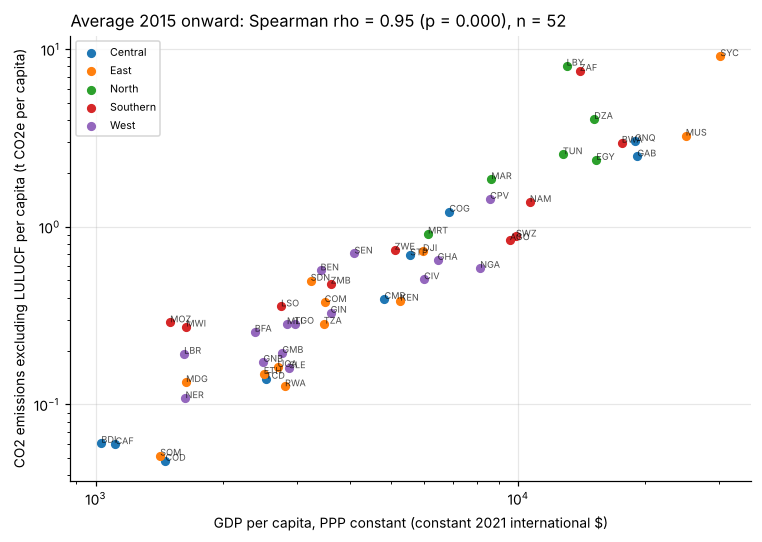

In [8]:
if has("G02", "A01"):
    s = afp[afp["year"] >= 2015].groupby(["iso3", "au_region"])[["G02", "A01"]].mean().dropna().reset_index()
    rho, p = stats.spearmanr(s["G02"], s["A01"])
    fig, ax = plt.subplots(figsize=(7, 5))
    for reg, g in s.groupby("au_region"):
        ax.scatter(g["G02"], g["A01"], label=reg, s=25)
    for r in s.itertuples():
        ax.annotate(r.iso3, (r.G02, r.A01), fontsize=6, alpha=0.7)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(label("G02")); ax.set_ylabel(label("A01"))
    print(f"H1 (descriptive): Spearman rho between GDP per capita and CO2 per capita = {rho:.2f} (p = {p:.3f}), n = {len(s)}")
    ax.set_title(f"Average 2015 onward: Spearman rho = {rho:.2f} (p = {p:.3f}), n = {len(s)}", loc="left"); ax.legend(fontsize=7)
    fig.tight_layout(); fig.savefig(OUT / "income vs co2.png", dpi=150); plt.show()

**H1 holds across countries: richer African countries emit much more CO2 per person (Spearman rho = 0.95, p < 0.001, n = 52).**

The within-country test, with controls, is in `08 Panel Models`.

## 8. Save tables

In [9]:
save_excel("carbon results.xlsx", {"CO2 pc latest": pc.set_index("iso3"), "CO2 total latest": share.set_index("iso3"),
                                   "Change pc": ch_pc, "Change total": ch_tot,
                                   **({"Intensity change": ci} if "ci" in globals() else {})})

['carbon results.xlsx',
 'co2 per capita ranking.png',
 'co2 per capita trend.png',
 'co2 total ranking.png',
 'income vs co2.png']

## What I found

- **Africa is a low emitter per person but concentrated in total.** The median country emits 0.49 t CO2e per person against a world average of 4.7 t, and five countries produce 72.7% of the continent's fossil CO2.
- **Growth is led by North Africa.** Egypt and Algeria together added 252 Mt since 2000 to 2002, more than the other eight countries in the top ten combined (226 Mt).
- **Methane matters more than CO2** for the median African country (56% of greenhouse gases against 18% globally).
- **Decoupling is partial:** CO2 intensity of GDP fell in only 51% of countries (H2 partly supported).
- **Fossil-only data misses the main story for forest economies:** land-use change is the larger CO2 source in 25 of 53 countries, including DR Congo, Zambia, Tanzania and Angola.
- **Income and emissions move together across countries** (rho = 0.95, H1 supported descriptively).

**Why it matters for finance:** for lenders, investors and treasury teams pricing climate exposure in Africa, emissions risk sits in two different places. In North and South Africa it is fossil CO2, exposed to carbon pricing and border adjustments such as the EU CBAM. In Central and Southern Africa it is land use and methane, where carbon-credit and deforestation-linked finance apply. A single per-capita CO2 metric captures neither well.